In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("winequality-white.csv", sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (4898, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


## 1. Dataset Inspection

The Wine Quality dataset contains 4,898 white wine samples and 12 columns. It includes 11 physicochemical features, such as acidity, residual sugar, chlorides, density, pH, and alcohol. The target variable is quality, which represents the wine quality score. Initial inspection is performed to understand the dataset structure, identify missing values and duplicate records, and examine descriptive statistics.

In [2]:
print("Dataset Information")
df.info()

print("\nMissing Values")
display(df.isnull().sum().to_frame(name="Missing Count"))

print("\nDuplicate Rows")
print(df.duplicated().sum())

print("\nDescriptive Statistics")
display(df.describe().round(2))

Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB

Missing Values


,Missing Count
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0



Duplicate Rows
937

Descriptive Statistics


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,4898.00,4898.00,4898.00,4898.00,4898.00,4898.00,4898.00,4898.00,4898.00,4898.00,4898.00,4898.00
mean,6.85,0.28,0.33,6.39,0.05,35.31,138.36,0.99,3.19,0.49,10.51,5.88
std,0.84,0.10,0.12,5.07,0.02,17.01,42.50,0.00,0.15,0.11,1.23,0.89
min,3.80,0.08,0.00,0.60,0.01,2.00,9.00,0.99,2.72,0.22,8.00,3.00
25%,6.30,0.21,0.27,1.70,0.04,23.00,108.00,0.99,3.09,0.41,9.50,5.00
50%,6.80,0.26,0.32,5.20,0.04,34.00,134.00,0.99,3.18,0.47,10.40,6.00
75%,7.30,0.32,0.39,9.90,0.05,46.00,167.00,1.00,3.28,0.55,11.40,6.00
max,14.20,1.10,1.66,65.80,0.35,289.00,440.00,1.04,3.82,1.08,14.20,9.00


## 2. Wine Quality Class Distribution

The target variable, quality, contains the wine quality scores. Examining the frequency of each score helps identify class imbalance. If some quality classes contain many more samples than others, a classifier may favour the majority class and perform poorly on underrepresented classes. This distribution will help guide the choice of classification strategy and evaluation metrics.

Wine Quality Class Counts


,Count
quality,
3,20
4,163
5,1457
6,2198
7,880
8,175
9,5


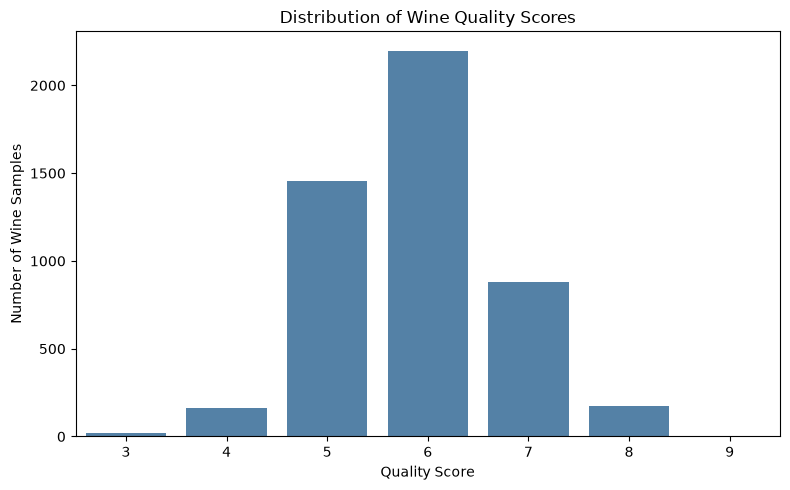

In [3]:
quality_counts = df["quality"].value_counts().sort_index()

print("Wine Quality Class Counts")
display(quality_counts.to_frame(name="Count"))

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="quality", color="steelblue")
plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Quality Score")
plt.ylabel("Number of Wine Samples")
plt.tight_layout()
plt.show()

## 3. Data Quality and Class Imbalance

The dataset contains no missing values, but 937 duplicate rows were identified. Duplicate records will be removed before model training to reduce repeated observations. The quality scores are also imbalanced: quality 6 is the most frequent class, while quality 9 has only five samples. This imbalance can cause a classifier to favour common classes and perform poorly on rare classes. Stratified splitting and class-sensitive evaluation will be considered to address this issue.

In [4]:
original_rows = len(df)

df = df.drop_duplicates().reset_index(drop=True)

print("Rows before removing duplicates:", original_rows)
print("Rows after removing duplicates:", len(df))
print("Duplicate rows remaining:", df.duplicated().sum())

print("\nUpdated quality distribution:")
display(df["quality"].value_counts().sort_index().to_frame(name="Count"))

Rows before removing duplicates: 4898
Rows after removing duplicates: 3961
Duplicate rows remaining: 0

Updated quality distribution:


,Count
quality,
3,20
4,153
5,1175
6,1788
7,689
8,131
9,5


## 4. Exploratory Data Analysis of Chemical Features

Histograms are used to examine the distributions of the 11 physicochemical features. They help reveal skewness, spread, concentration, and possible extreme values. Understanding feature distributions is useful before training classification models, particularly because some algorithms are sensitive to differences in feature scales.

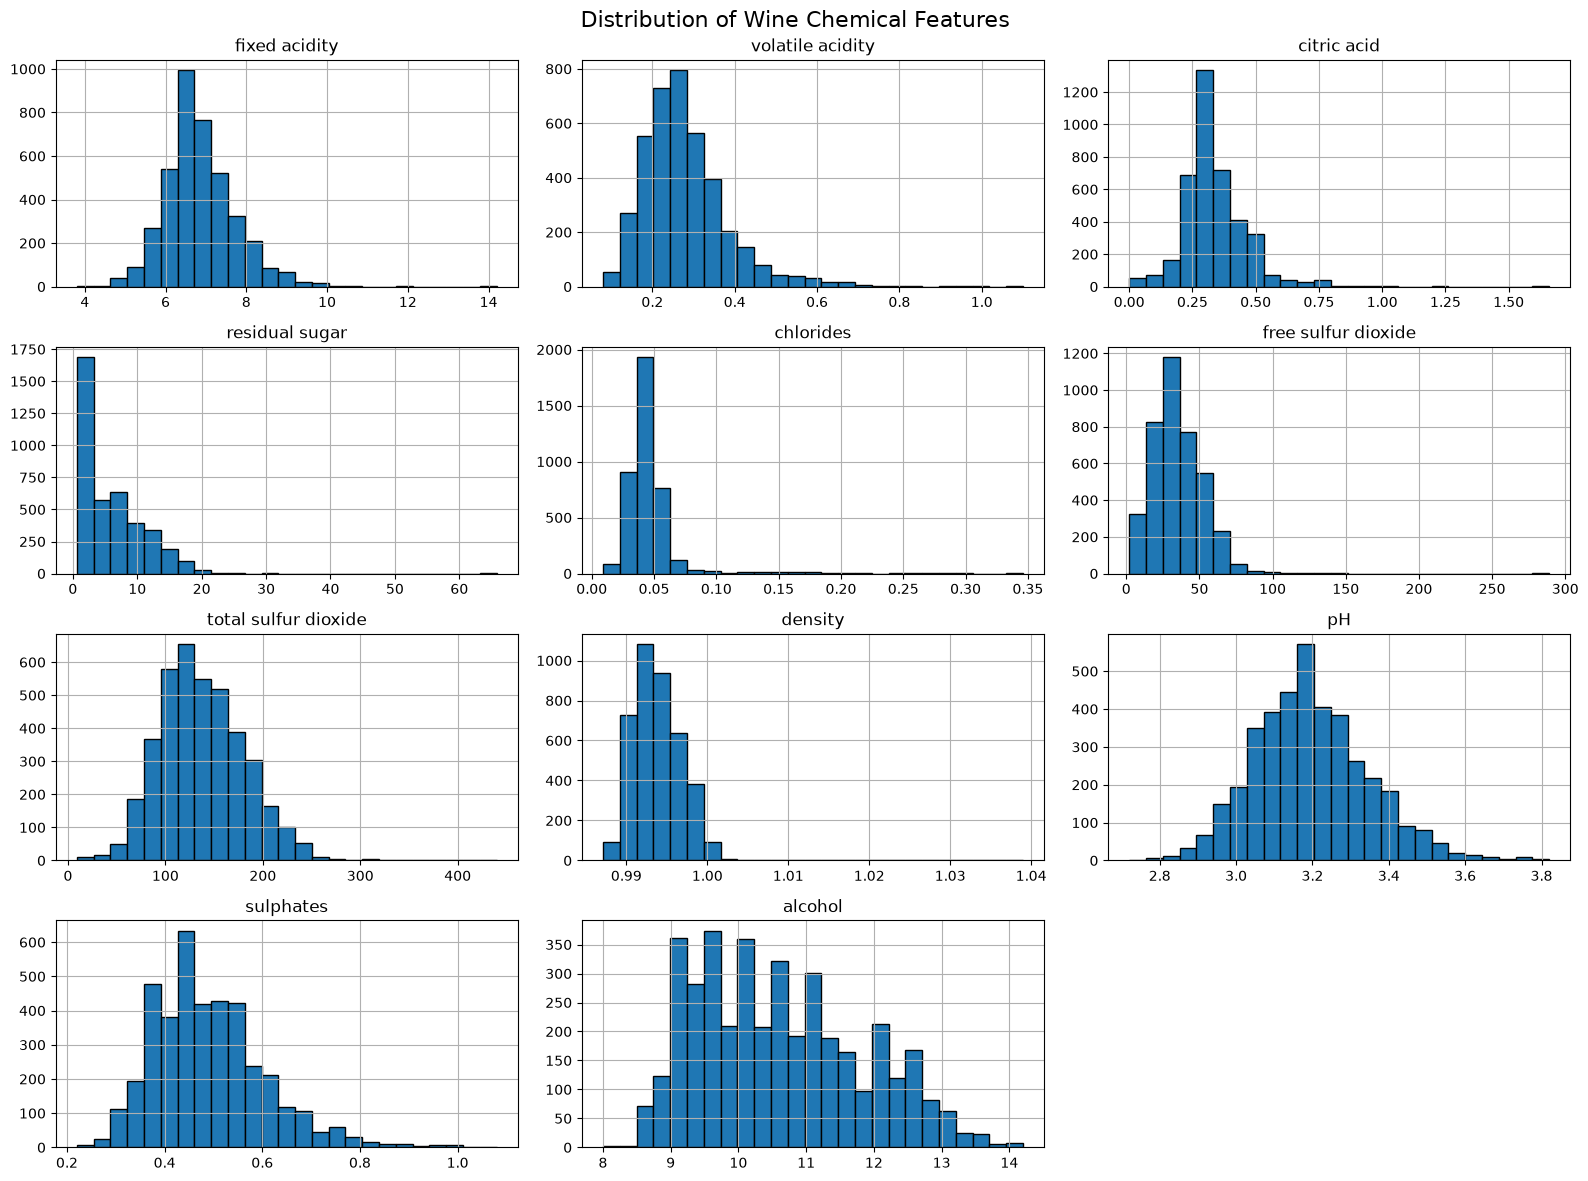

In [5]:
features = df.drop(columns=["quality"]).columns

df[features].hist(figsize=(16, 12), bins=25, edgecolor="black")
plt.suptitle("Distribution of Wine Chemical Features", fontsize=16)
plt.tight_layout()
plt.show()

## 5. Correlation Heatmap

A correlation heatmap shows the relationships between numerical features and the wine quality score. Correlation values range from -1 to +1. Positive values indicate that two variables tend to increase together, while negative values indicate an inverse relationship. This analysis helps identify chemical features that may be useful for predicting wine quality. However, correlation does not necessarily imply causation.

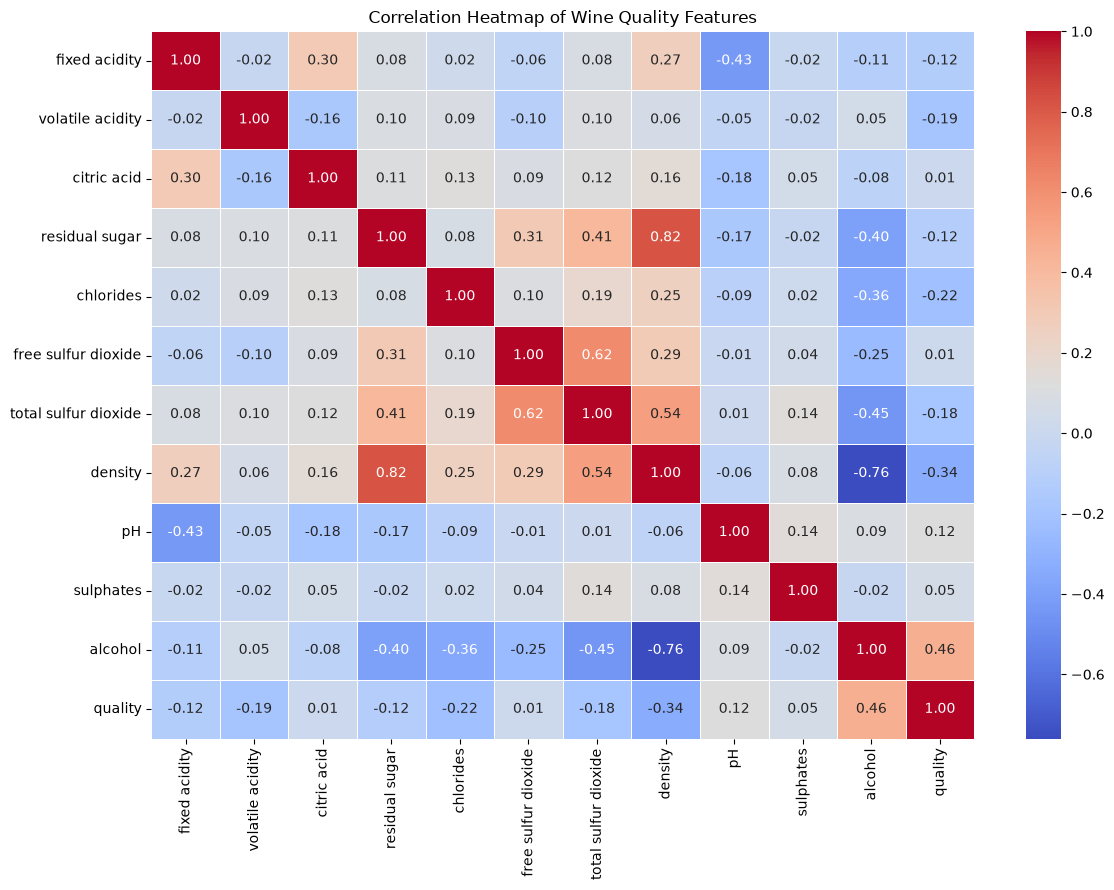

Correlation with quality:


,Correlation with Quality
alcohol,0.462869
pH,0.123829
sulphates,0.053200
free sulfur dioxide,0.010507
citric acid,0.007065
residual sugar,-0.117339
fixed acidity,-0.124636
total sulfur dioxide,-0.183356
volatile acidity,-0.190678
chlorides,-0.217739


In [6]:

plt.figure(figsize=(12, 9))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Wine Quality Features")
plt.tight_layout()
plt.show()

print("Correlation with quality:")

display(
    correlation["quality"]
    .drop("quality")
    .sort_values(ascending=False)
    .to_frame(name="Correlation with Quality")
)


## 6. Feature Engineering: Quality Classification

The original wine quality scores range from 3 to 9 and have an imbalanced distribution. To simplify the classification task, the scores are grouped into three categories: Low (quality 5 or below), Medium (quality 6), and High (quality 7 or above). This grouping reduces the number of target classes and combines rare quality scores into broader categories. Although some detailed score information is lost, the grouped target is more suitable for a practical classification experiment.

Quality Group Counts:


,Count
quality_group,
Low,1348
Medium,1788
High,825


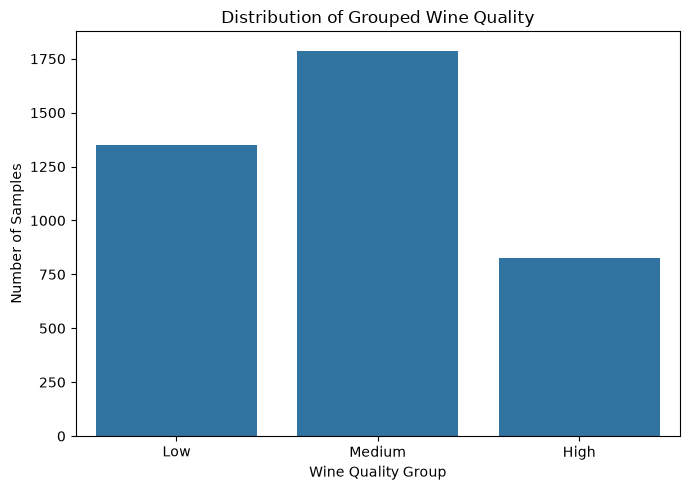

In [7]:

def quality_group(q):
    if q <= 5:
        return "Low"
    elif q == 6:
        return "Medium"
    else:
        return "High"

df["quality_group"] = df["quality"].apply(quality_group)

print("Quality Group Counts:")
display(df["quality_group"].value_counts().reindex(["Low", "Medium", "High"]).to_frame(name="Count"))

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="quality_group", order=["Low", "Medium", "High"])
plt.title("Distribution of Grouped Wine Quality")
plt.xlabel("Wine Quality Group")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


## 7. Feature Selection and Stratified Train-Test Split

The 11 physicochemical measurements are used as input features, while the grouped wine quality category is used as the target variable. The original numerical quality score is excluded from the input features to prevent target leakage. The dataset is divided into 80% training data and 20% testing data using stratified sampling. Stratification helps preserve the proportion of Low, Medium, and High quality categories in both sets.

In [8]:

from sklearn.model_selection import train_test_split

X = df.drop(columns=["quality", "quality_group"])
y = df["quality_group"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Total samples:", len(df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of input features:", X.shape[1])

print("\nTraining class distribution:")
display(y_train.value_counts().reindex(["Low", "Medium", "High"]).to_frame(name="Count"))

print("\nTesting class distribution:")
display(y_test.value_counts().reindex(["Low", "Medium", "High"]).to_frame(name="Count"))


Total samples: 3961
Training samples: 3168
Testing samples: 793
Number of input features: 11

Training class distribution:


,Count
quality_group,
Low,1078
Medium,1430
High,660



Testing class distribution:


,Count
quality_group,
Low,270
Medium,358
High,165


## 8. Model Training

Three classification algorithms are used to predict the grouped wine quality: Random Forest, Stochastic Gradient Descent (SGD) Classifier, and Support Vector Classifier (SVC). Random Forest combines multiple decision trees, SGD learns model parameters through iterative optimization, and SVC identifies decision boundaries between classes. StandardScaler is included in the pipelines to scale input features for consistent preprocessing. Scaling is particularly important for SGD and SVC. All preprocessing and model fitting are performed using the training data only.

In [9]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC

models = {
    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        ))
    ]),
    "SGD Classifier": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SGDClassifier(
            max_iter=2000,
            tol=1e-3,
            random_state=42,
            class_weight="balanced"
        ))
    ]),
    "SVC": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            class_weight="balanced"
        ))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")


Random Forest trained successfully!
SGD Classifier trained successfully!
SVC trained successfully!


## 9. Model Evaluation

The trained classifiers are evaluated using the testing dataset. Accuracy measures the overall proportion of correct predictions, while precision measures the correctness of positive predictions for each class. Recall measures how many actual samples of each class are correctly identified, and the F1-score balances precision and recall. Confusion matrices are used to examine correct and incorrect predictions across the Low, Medium, and High wine quality categories. The classification report provides a detailed evaluation of each model.


Random Forest
Accuracy: 0.6003

Classification Report:
              precision    recall  f1-score   support

         Low       0.66      0.63      0.64       270
      Medium       0.58      0.58      0.58       358
        High       0.55      0.59      0.57       165

    accuracy                           0.60       793
   macro avg       0.60      0.60      0.60       793
weighted avg       0.60      0.60      0.60       793



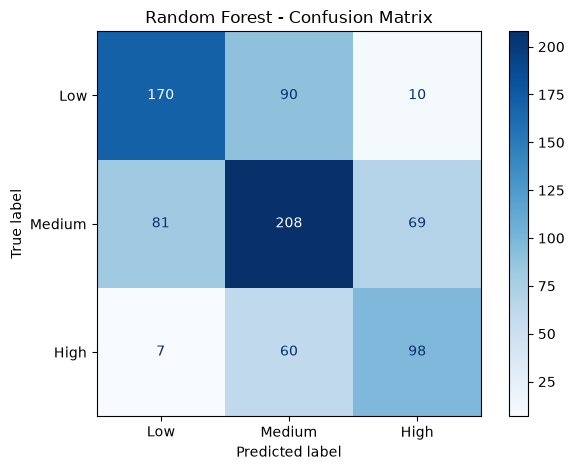


SGD Classifier
Accuracy: 0.5069

Classification Report:
              precision    recall  f1-score   support

         Low       0.51      0.76      0.61       270
      Medium       0.53      0.29      0.37       358
        High       0.47      0.57      0.51       165

    accuracy                           0.51       793
   macro avg       0.51      0.54      0.50       793
weighted avg       0.51      0.51      0.48       793



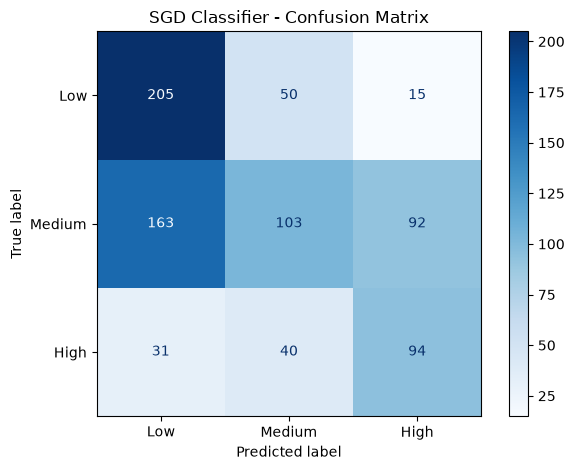


SVC
Accuracy: 0.5637

Classification Report:
              precision    recall  f1-score   support

         Low       0.66      0.71      0.68       270
      Medium       0.58      0.40      0.48       358
        High       0.44      0.67      0.53       165

    accuracy                           0.56       793
   macro avg       0.56      0.60      0.56       793
weighted avg       0.58      0.56      0.56       793



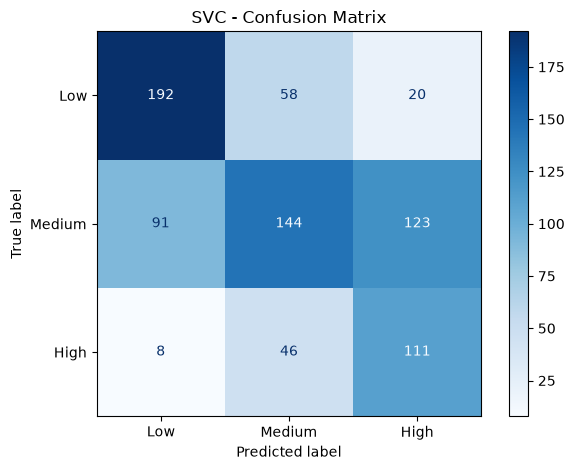

In [10]:

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

labels = ["Low", "Medium", "High"]
results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": round(accuracy, 4)
    })

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)
    print("Accuracy:", round(accuracy, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=labels,
        target_names=labels,
        zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred, labels=labels)

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )

    display_matrix.plot(cmap="Blues", values_format="d")
    plt.title(name + " - Confusion Matrix")
    plt.tight_layout()
    plt.show()


## 10. Feature Importance Analysis

Random Forest feature importance is used to identify which chemical measurements contribute most to the model's predictions. The importance scores indicate the relative contribution of each feature within the trained model. These scores help interpret the model and understand which measurements are most useful for distinguishing wine quality groups. Feature importance does not imply that a feature directly causes higher or lower wine quality.

,Feature,Importance
10,alcohol,0.148256
7,density,0.116197
1,volatile acidity,0.094430
5,free sulfur dioxide,0.091736
6,total sulfur dioxide,0.087837
4,chlorides,0.087062
3,residual sugar,0.080011
8,pH,0.078849
2,citric acid,0.075665
9,sulphates,0.071910


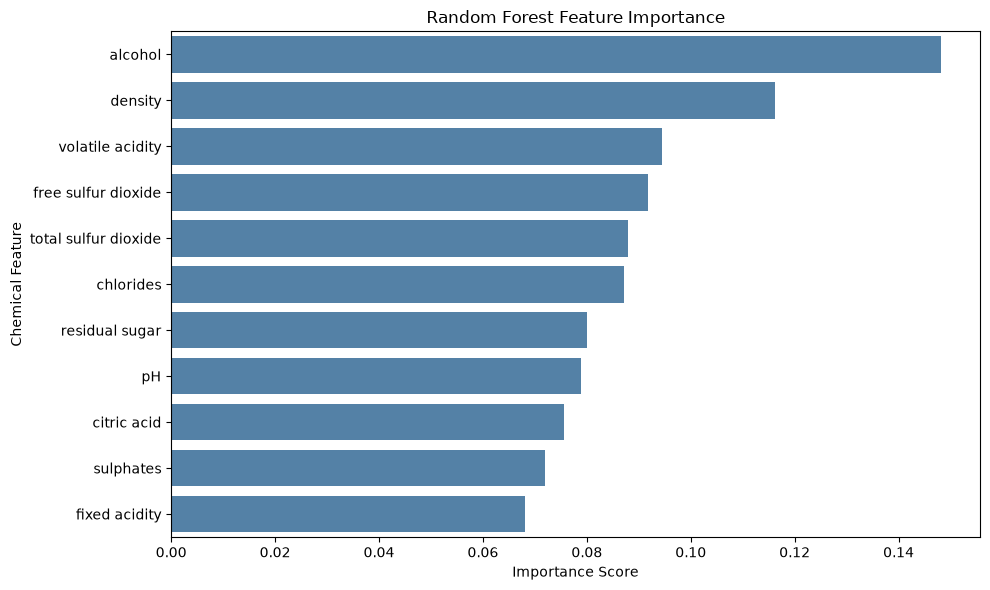

In [11]:

rf_model = models["Random Forest"].named_steps["classifier"]

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    color="steelblue"
)
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Chemical Feature")
plt.tight_layout()
plt.show()


In [12]:

comparison_df = pd.DataFrame(results)
comparison_df = comparison_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

comparison_df["Accuracy (%)"] = (
    comparison_df["Accuracy"] * 100
).round(2)

display(comparison_df[["Model", "Accuracy (%)", "Accuracy"]])


,Model,Accuracy (%),Accuracy
0,Random Forest,60.03,0.6003
1,SVC,56.37,0.5637
2,SGD Classifier,50.69,0.5069


## 11. Results and Discussion

Three machine learning classifiers were evaluated for predicting wine quality groups. Random Forest achieved the highest accuracy of 60.03% and a macro F1-score of 0.60. SVC achieved 56.37% accuracy, while SGD Classifier achieved 50.69%.

The Random Forest model performed best overall among the three evaluated classifiers. Its classification report showed comparatively balanced performance across the Low, Medium, and High categories. However, the results indicate moderate predictive performance, and further improvements are needed before practical use.

The Random Forest feature importance analysis identified alcohol as the most important feature, followed by density and volatile acidity. These results show that the model relies on multiple physicochemical measurements when distinguishing wine quality groups.

## 12. Conclusion and Deployment Recommendation

This project demonstrates how machine learning can classify white wine samples into Low, Medium, and High quality categories using physicochemical measurements. Among the three models tested, Random Forest achieved the highest test accuracy of 60.03%, making it the preferred candidate for further development.

For a demonstration or prototype, Random Forest can be selected as the initial model. Before real-world deployment, additional validation, hyperparameter tuning, and evaluation on independent wine samples are required. The model should be treated as a decision-support tool rather than a definitive measure of wine quality.